# DeviceLayout.jl SingleTransmon: a rectangle transmon with a clawed λ/4 readout, rebuilt in the Quantcore PDK step by step

**Source:** AWS Center for Quantum Computing, **DeviceLayout.jl**, `examples/SingleTransmon/SingleTransmon.jl` and the
docs page `docs/src/examples/singletransmon.md`, with the components `ExampleRectangleTransmon` and
`ExampleClawedMeanderReadout` from `src/schematics/ExamplePDK`, <https://github.com/aws-cqc/DeviceLayout.jl>, **MIT
licence** ("Copyright Amazon.com, Inc. or its affiliates", `LICENSE.md`; depth-1 clone read 2026-11-03 into
`build/external/DeviceLayout.jl`, Julia, never run). We distribute the rebuild under GPL-3.0. Spec:
`docs/designs/devicelayout/singletransmon.md`. Source figure: `docs/src/assets/single_transmon_mesh.png` (the Palace
mesh).

**What the chip is:** a Palace eigenmode example, not a fab layout. A grounded rectangular transmon island
(24 × 620 µm in a 30 µm gap) is read out by a λ/4 meander. The line is shorted at the far end of a 400 µm coupled
section beside a straight 2700 µm feedline (5 µm ground strip), leaves it through a 500 µm leg, meanders (5 turns,
r 50 µm) and ends in a claw that wraps the island's near end. The Palace model has lumped ports at both feedline ends
and airbridges every 300 µm; its targets are 3.370 GHz (qubit) and 5.244 GHz (resonator).

**This notebook rebuilds it in the Quantcore PDK; it is not a replica.** What the rebuild keeps and what the PDK
changes:

| topic | source (DeviceLayout.jl) | this rebuild |
|---|---|---|
| die and frame | a 4 × 3.7 mm Palace domain, no frame | PDK 7.5 mm die with dicing L's, alignment grids, device ID `DL-ST` |
| stack | sapphire (Palace: εr 9.3 / 9.3 / 11.5) | PDK sapphire 650 µm, εr 10.25 |
| qubit | `ExampleRectangleTransmon` (island 24 × 620 µm, 30 µm gap, 12 µm junction gap) | KQC `Swissmon` with short W/E arms and the same island, gaps and claw (the 2 µm claw shield is not drawn) |
| junction | lumped L_J 14.860 nH, C 5.5 fF | Quantcore trilayer junction sized for 4.05 GHz (the source's 3.37 GHz is below the PDK band); R_n ≈ 120 kΩ flagged, not retuned |
| readout | 5000 µm λ/4, 400 µm coupled section, 5 µm strip, 5 meander turns | the same lengths, a qcc hanger on the feedline (`near=`: the coupler stays where it was) |
| feedline ports | lumped ports at the domain edge | two `BondPad`s; **PDK pad rule**: `frame.pad_edge` = 100 µm from the die edge, so the feedline runs die edge to die edge |
| placement | domain centred on the feedline system | **PDK**: the content is centred in the die |
| airbridges | every 300 µm on every path | omitted (KQC's auto bridges across the coupled section shorted to the neighbouring line) |
| cheese | none (a simulation example: no ground holes in `SingleTransmon.jl`) | **PDK band** (`cheese: "auto"`) |
| netlist, LOM, FEM | Palace eigenmodes | our netlist and LOM, Q3D and eigenmode job exports |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die, the two pads that end the feedline, the feedline, the junction and the rectangle transmon, its clawed λ/4 readout on the feedline, and then the whole chip (the targets, the sim group, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `singletransmon.v1.ipynb`; both save the same `singletransmon.json`.

## Setup

The imports, the output folder and the switches. The notebook runs from the repository root; the segment
pictures and the snapshots go next to the notebook (`examples/designs/devicelayout/singletransmon_*.png`).

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/devicelayout")
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on. The frame and the cheese band are drawn by the chip build, the pad rule by `edge=`,
the junction by `trilayer_junction`; the PDK design warnings come out of the DRC.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die, the bond pads, the readout line, the qubit,
its readout resonator, and then the whole chip. Each segment is one cell with one picture of the chip so far (live,
KLayout redraws after every cell). A route joins two ports, or a port and a hanger on another route, so the feedline
is drawn before the qubit and the readout after it (it starts at the claw and hangs on the feedline). Coordinates are
the source's ≈ + (870, 500) µm until the centring in Design 8.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm Quantcore die with its frame (device ID DL-ST) |
| 2 | the two bond pads that end the feedline (the source's Palace ports), on the south / north die edges |
| 3 | the readout line: the feedline between them |
| 4 | the junction (sized on the PDK rule) and the rectangle transmon (a KQC `Swissmon` stand-in) |
| 5 | the clawed λ/4 readout, from the claw to a shorted hanger on the feedline |
| 6 | the coupling: none (one qubit) |
| 7 | the control routing: none (the source has no drive or flux line) |
| 8 | the whole chip: the targets, the sim group, the centring, save |

## Design 1 · The die and the frame

The source is a 4 × 3.7 mm simulation domain; the rebuild puts it on the PDK's standard 7.5 mm die, with the
domain's coordinates kept: Designer ≈ source + (870, 500) µm, and the box `(-1750, -1900, 5750, 5600)` is the 7.5 mm
die round the domain. The PDK draws the frame (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary
100/0) and the device ID `DL-ST` on a free edge. `SingleTransmon.jl` has no ground-plane holes (DemoQPU17 adds them
with `autofill!`; this example does not), so the default `cheese: "auto"` gives the PDK band.

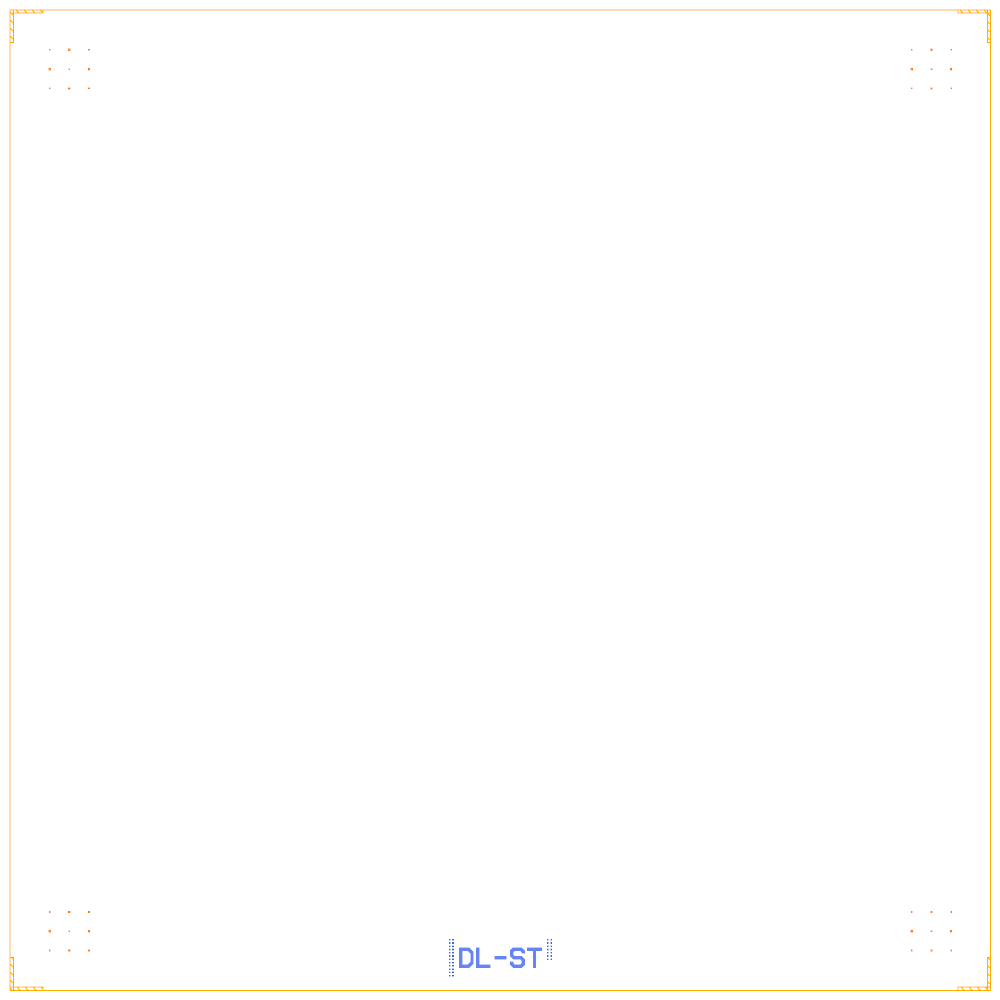

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/devicelayout/singletransmon_die.png')

In [5]:
d = Designer("singletransmon", box=(-1750, -1900, 5750, 5600), chip={"name_chip": "DL-ST"}, live=LIVE)
layout_step(d, OUT / "singletransmon_die.png", size=(1000, 1000), width=360)

## Design 2 · Bond pads: the feedline ends

The source has no pads: the feedline ends in Palace lumped ports at its two end points (870, 500) and (870, 3200). The
rebuild terminates it with two small KQC `BondPad`s (200 × 200 µm, 150 µm taper), the south one facing north and the
north one facing south. The PDK puts every bond pad and launcher with the outer edge of its etch **`frame.pad_edge` =
100 µm from the die edge**: `edge="auto"` slides each pad perpendicular to its nearest die edge (here
south and north) until that holds, keeping its x. `pads_md(d)` lists each pad's distance to the nearest edge.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_S | `BondPad` | s | 100.0 | ✓ |
| P_N | `BondPad` | n | 100.0 | ✓ |

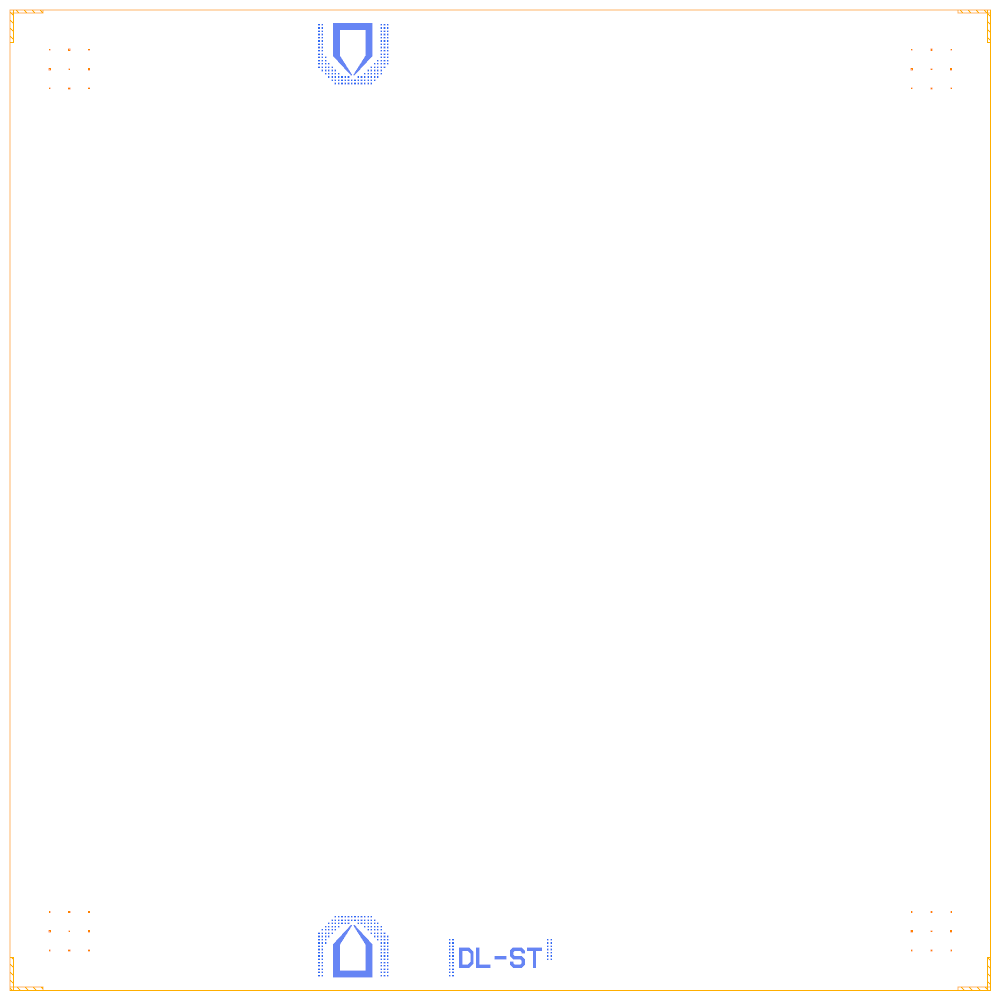

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `P_S`, `P_N`.

WindowsPath('examples/designs/devicelayout/singletransmon_s2_pads.png')

In [6]:
XF, Y0 = 870, 500                                # feedline x and the source's start (source (0, 0) → (870, 500))
PAD = dict(pad_width=200, pad_height=200, taper_length=150, pad_gap=50)
ps = d.add("P_S", "BondPad", at=(XF, Y0), rot=0, edge="auto", **PAD)            # faces north
pn = d.add("P_N", "BondPad", at=(XF, Y0 + 2700), rot=180, edge="auto", **PAD)   # faces south
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "singletransmon_s2_pads.png", size=(1000, 1000), width=360)

## Design 3 · Readout: the feedline

**The feedline** is a straight CPW (PDK default 10/6 µm, bend radius 50 µm) between the pads' ports `a`. With the pads
at the die edges it runs the full die height instead of the source's 2700 µm; a 50 Ω through-line, so its length sets
no frequency. The readout hangs on it (Design 5).

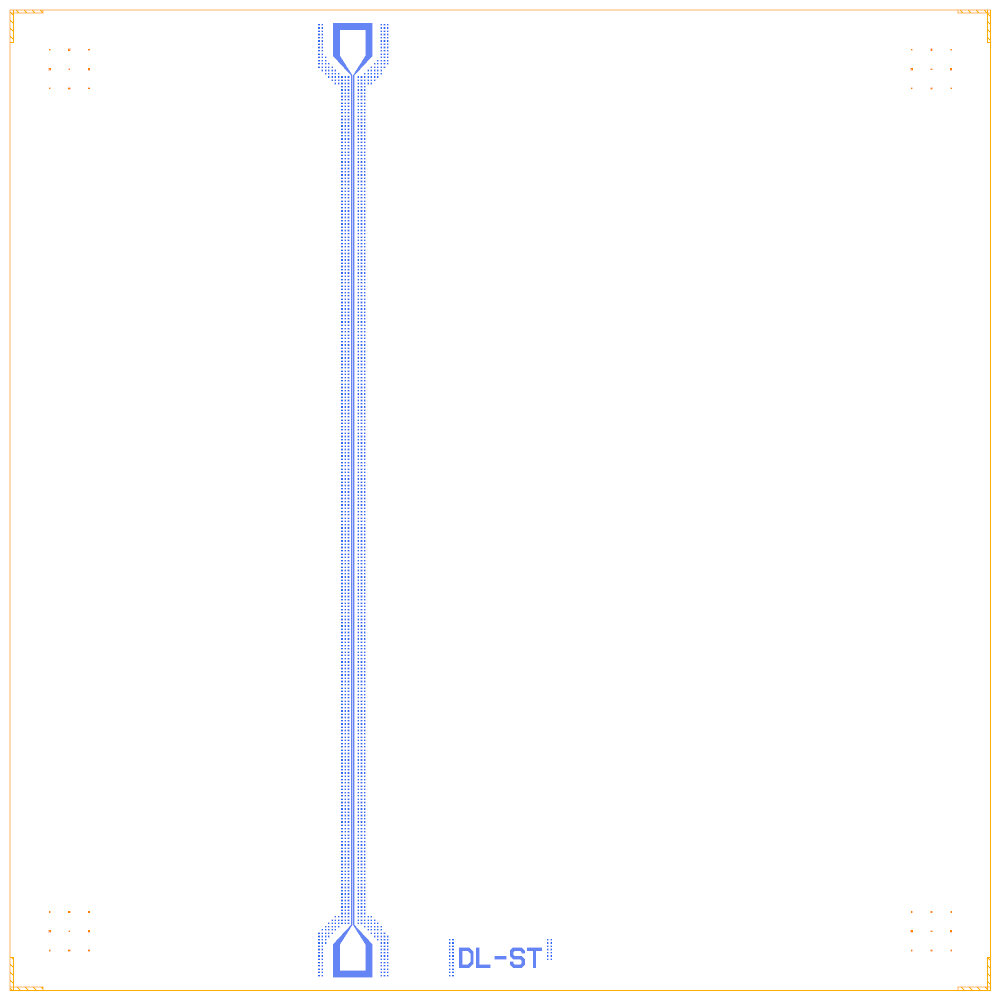

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `FL`.

WindowsPath('examples/designs/devicelayout/singletransmon_s3_feedline.png')

In [7]:
fl = d.route("FL", ps.a, pn.a, r=50)
layout_step(d, OUT / "singletransmon_s3_feedline.png", size=(1000, 1000), width=360)

## Design 4 · Qubit placement: the junction and the rectangle transmon

**The junction.** The source's qubit is at 3.37 GHz, below the PDK's 4–8 GHz band, so the junction is sized for
4.05 GHz instead. `size_junction(f_q, C_Σ)` uses the LOM C_Σ of this island without the junction (69.6 fF, from the
design's LOM before the rebuild) and returns L_J ≈ 17.7 nH and a straight finger of ≈ 0.19 µm (KQC's
`junction_width`) × 0.6 µm: **R_n ≈ 120 kΩ, above the 40–50 kΩ window** (a 45 kΩ junction would put the qubit at
≈ 6.4 GHz, above the 5.24 GHz readout). Following the project rule, it is flagged (DRC `pdk_rn`; `pdk_fq` on the
source's 3.37 GHz target), not retuned; the targets stay the source's.

In [8]:
SIZED = size_junction(4.05, 69.6, c_includes_junction=False)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=SIZED.lj_nH)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JUNCTION, f"→ R_n {SIZED.rn_kohm:.0f} kΩ;", *SIZED.notes)

cell parameters: {'junction_type': 'Quantcore Junction', 'junction_width': 0.19}
LOM junction:    {'Lj_nH': 17.7222, 'Cj_fF': 5.7} → R_n 121 kΩ; R_n 121.4 kΩ is outside the process window 40–50 kΩ (f_q 4.05 GHz with C_Σ 75.2 fF needs E_J/h 9.0 GHz)


**The qubit.** The rectangle island is a KQC `Swissmon` with short west/east arms (`arm_length` [12, 298, 12, 298],
24 µm wide, so the island is 24 × 620 µm), the 30 µm gap all round and a 12 µm gap on the junction side. Its north-arm
claw coupler is the readout claw: trace 34 µm, length 121 µm, gap 6 µm, grasp width 84 µm = 24 + 2 × 30. Rotated by
90°, the claw points west towards the feedline.

<Swissmon Q ports=['cplr0', 'cplr1', 'cplr2', 'drive']>


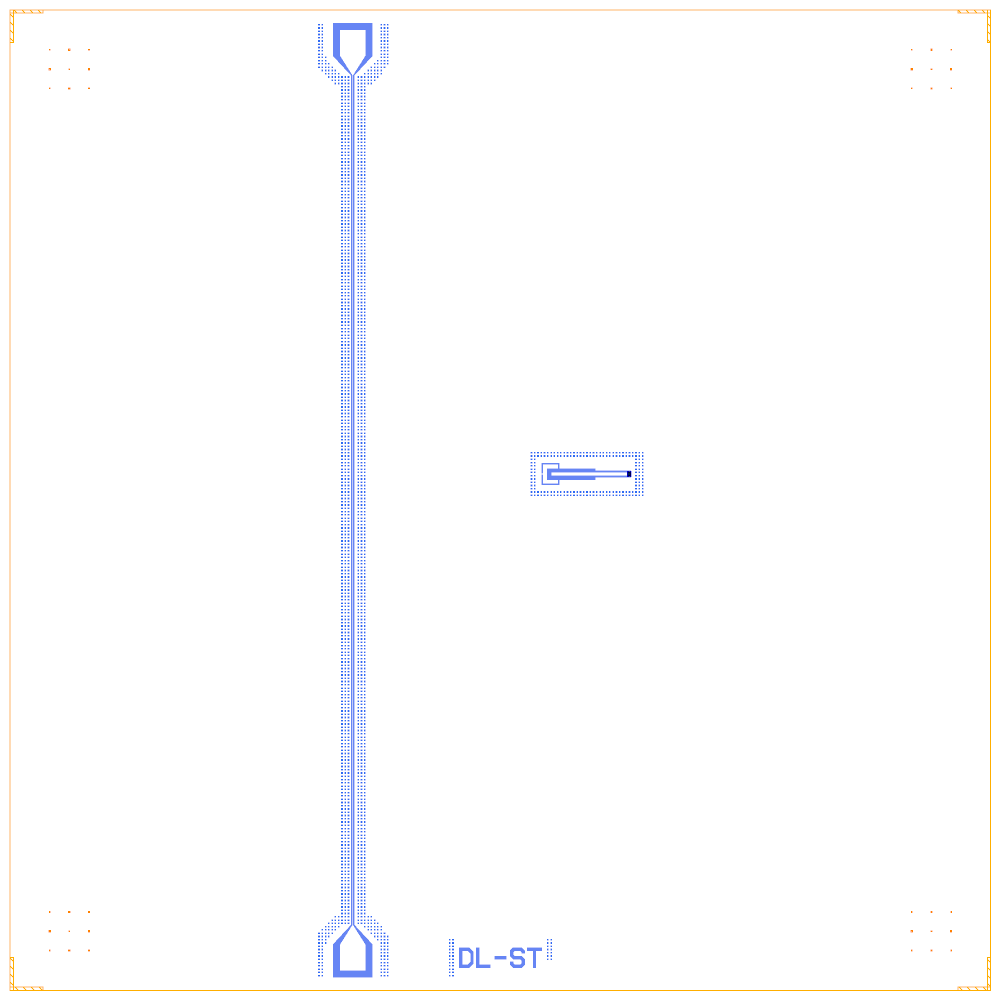

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `Q`.

WindowsPath('examples/designs/devicelayout/singletransmon_components.png')

In [9]:
RECT_TRANSMON = dict(fluxline_type="none", arm_length=[12, 298, 12, 298], arm_width=[24] * 4,
                     gap_width=[30, 30, 30, 12], island_r=0,
                     cpl_length=[0, 121, 0], cpl_width=[24, 34, 24], cpl_gap=[84, 84, 84])   # N-arm claw
q = d.add("Q", "Swissmon", at=(2685, 2050), rot=90, junction=JUNCTION, **JJ_PARAMS, **RECT_TRANSMON)
print(q)
layout_step(d, OUT / "singletransmon_components.png", size=(1000, 1000), width=360)

## Design 5 · Readout: the clawed λ/4 readout

**The readout** runs from the claw (`Q.cplr1`) through a 500 µm leg to the feedline and ends in `fl.hanger(...)`: a
400 µm section coupled to the feedline across a 5 µm ground strip, shorted at its south end (`direction="backward"`).
`near=(x, y)` centres the coupler at the feedline point nearest (x, y): (897, 1850), where the source has it (y 1650 to
2050). Given by `near=` instead of an arclength `s=` from the feedline start, the coupler does not slide when the pads
(and so the feedline's start) move. The total length is the source's 5000 µm with 5 meander turns (r 50 µm); the
waypoint puts the 500 µm leg's end in front of the claw.

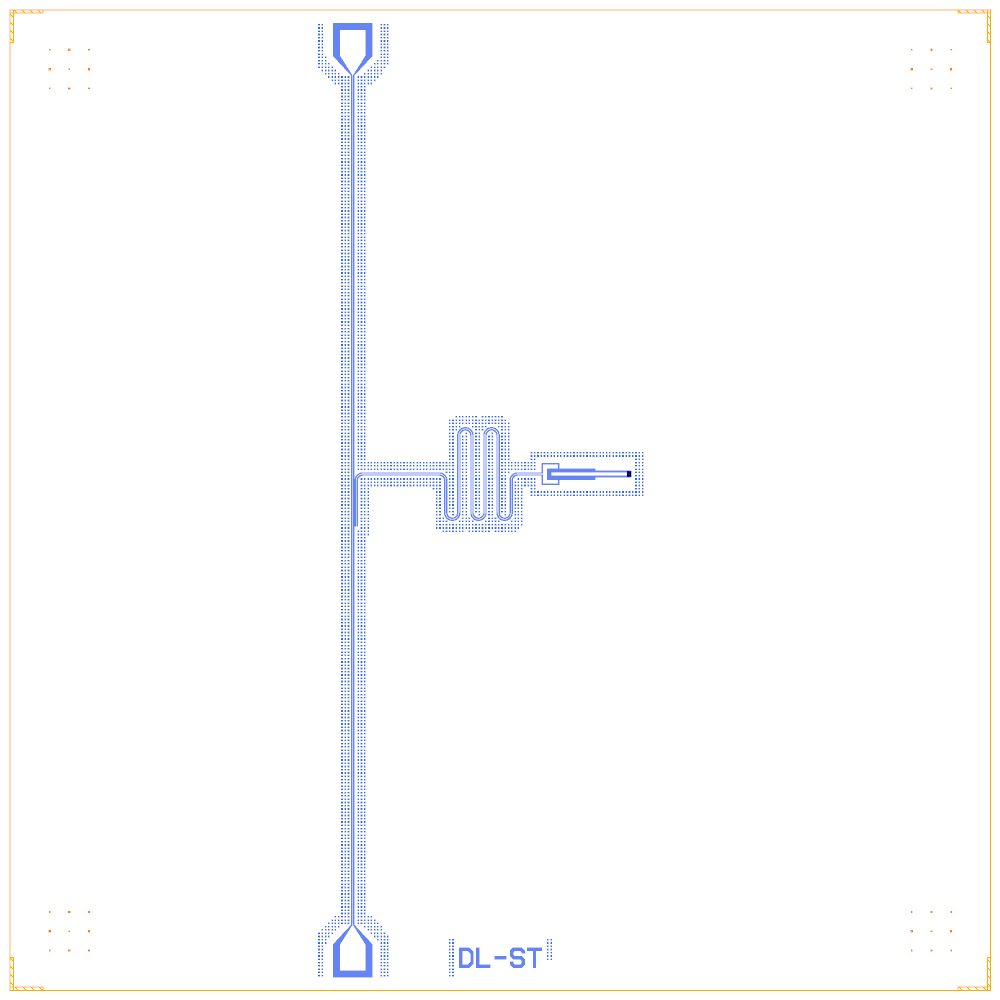

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 2 routes · 0 declared couplings. **This step added** 1 route(s) `R`.

{'FL': 6500.0, 'R': 5000.0}


In [10]:
ro = d.route("R", q.cplr1, fl.hanger(near=(XF + 27, 1850), length=400, side="right", ground_gap=5,
                                     direction="backward", end="short"),
             meander=5000, r=50, nodes=[(XF + 27 + 500, 2050)]).set(meanders=5)
layout_step(d, OUT / "singletransmon_s5_readout.png", size=(1000, 1000), width=360)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})

## Design 6 · Coupling: none (one qubit)

## Design 7 · Routing: no control lines

The source qubit has no drive or flux line: the stand-in `Swissmon`'s unused couplers and its `drive` port stay open
(Check 1 lists them).

## Design 8 · The whole chip: targets, sim group, centring, save

**Targets and sim group.** The Palace targets go into the design (qubit 3.370 GHz, resonator 5.244 GHz; the
qubit's is below the PDK band, so the DRC flags it, `pdk_fq`); one sim group holds the qubit, the readout and the
feedline (a Q3D C-matrix and an eigenmode / EPR job).

**Centring.** `center_in_die(d)` measures the bounding box of every instance and route and shifts them all (instance positions,
route waypoints, hanger `near` points) so that box is centred in the die. The pads sit on the north and south edges,
so the shift is along x only and the pad rule still holds. The shift: (+142.5, 0) µm.

**Save.** `save_design` writes the JSON and compares it with the file it replaces (the previous run's, saved in the
v1's FEM cell): the segments above changed how the chip is built, not the chip, so it should say *same design*; the
file keeps the previous key order.

shift applied (µm): (142.5, 0.0)


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_S | `BondPad` | s | 100.0 | ✓ |
| P_N | `BondPad` | n | 100.0 | ✓ |

**Same design as before:** `examples/designs/devicelayout/singletransmon.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

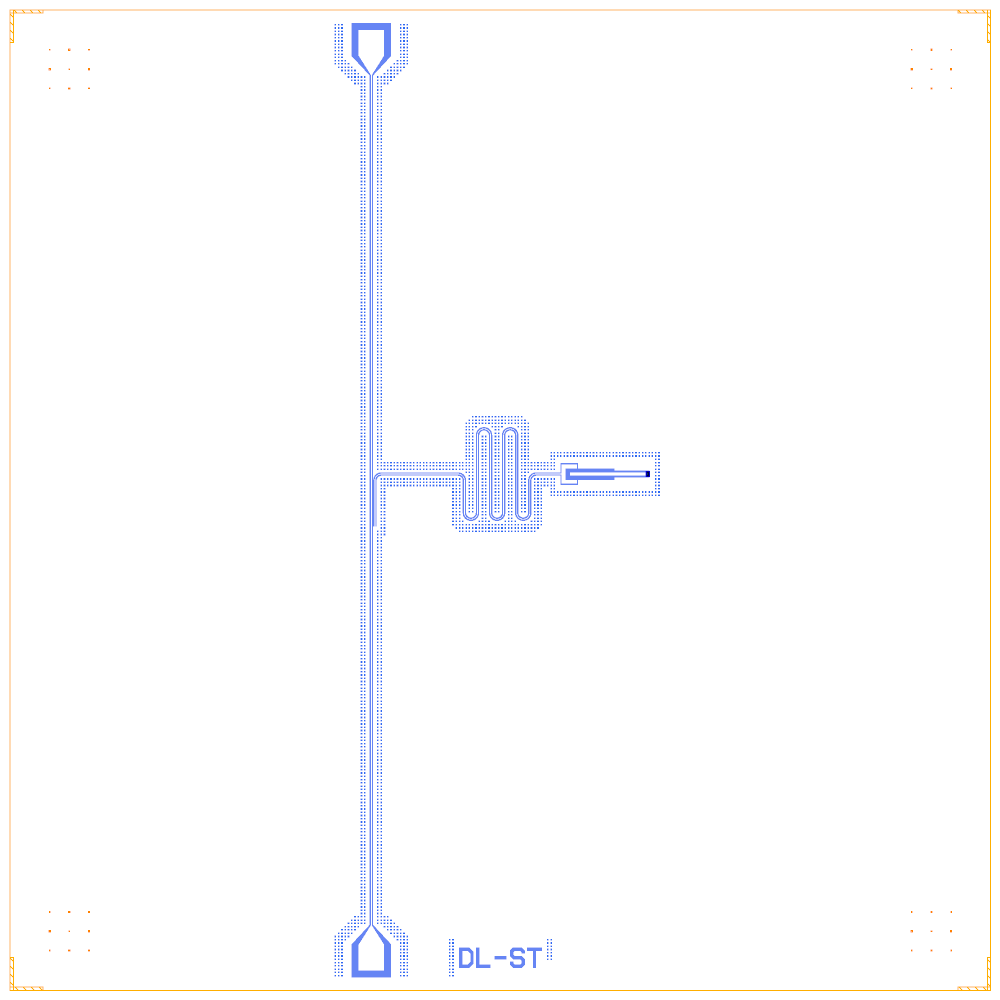

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 2 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/devicelayout/singletransmon_routes.png')

In [11]:
d.targets(Q={"f_q_GHz": 3.370}, R={"f_GHz": 5.244})
d.sim_group("QR", ["Q", "R", "FL"])
rebuild(d)
shift = center_in_die(d)
print("shift applied (µm):", shift)
QX, QY = d.data["instances"]["Q"]["place"]["at"]   # the qubit after centring (snapshot boxes below)
XF = XF + shift[0]
rebuild(d)
display(Markdown(pads_md(d)))
DESIGN, same = save_design(d, OUT / "singletransmon.json")
display(Markdown(same))
layout_step(d, OUT / "singletransmon_routes.png", size=(1000, 1000), width=360)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (dangling ports, overlaps, route crossings, netlist opens and shorts) and the PDK
margins. There are three kinds of finding:
- **errors** would make the chip wrong; there must be none;
- **warnings** are worth a look but can be intended: here the stand-in Swissmon's unused couplers `cplr0` / `cplr2`
  (zero length) and its `drive` port (the source qubit has no drive line);
- **PDK design warnings** flag values outside the PDK margins: `pdk_rn` (R_n ≈ 118 kΩ) and `pdk_fq` (the source's
  3.37 GHz target, below 4 GHz). They are reported, never enforced.

Expected (from the v1 run): **no errors**; 3 `dangling_port` warnings (`cplr0`, `cplr2`, `drive`); `pdk_rn` (118.4 kΩ) and
`pdk_fq`. No `pad_edge`: both pads sit at 100 µm.

`pdk_report(d)` sums up the PDK checks: cheese source, centring, junction types, design warnings.

In [ ]:
rebuild(d)
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: the Swissmon's LOM model gives the grounded island node with its
junction to ground and the claw coupler node (C_g to the island); the readout is a λ/4 `TLres` with a `HANGER` (κ) to
the feedline node, which carries the two pads' 50 Ω ports.

In [ ]:
lb = d.lom()
show_netlist(lb)
print(lom_summary(lb))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation (whole circuit) vs the Palace eigenmodes

QuCat normal modes of the whole circuit, then the QuTiP dressed values, next to the Palace targets (3.370 GHz qubit,
5.244 GHz resonator). The qubit lands near the 4.05 GHz it was sized for, not at the source's 3.37 GHz; the stand-in
island and the substrate model also shift the resonator. From the v1 run: f_q **4.095 GHz**, α −307 MHz; f_r **5.683 GHz**,
8 % above Palace's 5.244 GHz (sapphire εr 10.25 against Palace's anisotropic 9.3 / 11.5, and the claw's loading);
κ 0.224 MHz through the 400 µm coupler; χ −0.71 MHz.

In [ ]:
res = simulate_lom(lb, d.design)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res, {"Q": {"f_q_GHz": 3.370}, "R": {"f_GHz": 5.244}})))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) the normal modes (QuCat; the circle is the qubit, the square the readout; filled
markers are the QuTiP dressed values; red bars are the Palace targets), (b) the readout's dispersive shift |χ|.

In [ ]:
plot_lom({"chip": res}, OUT / "singletransmon_lom.png", targets={"Q": {"f_q_GHz": 3.370}, "R": {"f_GHz": 5.244}},
         title="singletransmon: LOM")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The LOM is cheap, so a design change can be checked in seconds. Here the claw is lengthened from 121 to 150 µm: it
wraps more of the island, so the coupling capacitance, g and χ grow, and the qubit moves down a little (more C_Σ). From the v1 run: χ −0.708 → −1.109 MHz, f_q 4.095 → 4.070 GHz, and the readout
moves down too (5.683 → 5.602 GHz: the longer claw loads its open end).
`design_copy` opens a second, non-live Designer on the saved design, so the design file stays as it is.

In [ ]:
d2 = design_copy(DESIGN)
d2["Q"].set(cpl_length=[0, 150, 0])
res2 = simulate_lom(d2.lom(), d2.design)
display(Markdown(params_delta_md(res, res2)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/devicelayout/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The sim group `QR` (qubit, readout, feedline) is exported as a Q3D C-matrix job (capacitances by net name) and an
eigenmode/EPR job; the feedline ends in its pads' 50 Ω ports, as the Palace model's lumped ports. Job folders are
self-contained (`build/jobs/<design>_<group>_<analysis>`); exporting again replaces a folder, results included.
Simulation exports never carry cheese.

`RUN_FEM = False` only exports. `FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. On another
machine: `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/devicelayout/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["QR"])
jobs_eig = export_sims(DESIGN, ["QR"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of the group `QR`: the island, the claw, the readout and the feedline as named nets. Each net is named
after its LOM node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves the job with
`RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same box in HFSS eigenmode — what the source ran in Palace: the junction is a lumped L_J ‖ C_J sheet, the
feedline ends in the pads' 50 Ω ports, so each mode's Q gives κ. pyEPR (run inside qcc's own AEDT, never KQC's
`run_pyepr_t1_estimate.py`) turns the junction's energy participation p_J into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 along the feedline, where the λ/4 shows up as a notch. The library cannot hand the solved
eigenmode **mesh** itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest
thing: the same sim group and box, the eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's
readout mode (the LOM's f_r before the eigenmode is solved) and a fast sweep around it.

In [ ]:
f_r = res.params.get("R.f_GHz")                          # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "QR", jobs_eig["QR"][0], keep_eig["QR"], f_guess=f_r)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["QR"]:
    display(Markdown(driven_md(keep_drv["QR"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit; ≈ 0: the readout), with the LOM's frequencies as dashed
lines. The table below lists the modes and the pyEPR values — the rebuild's counterpart of the source's Palace run.

In [ ]:
lom_f = {"Q": res.params.get("Q.f_q_GHz"), "R": f_r}
plot_eigenmodes(keep_eig, OUT / "singletransmon_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: the qubit's mode is the one its junction participates in most, the readout's the
remaining mode nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms, κ = f/Q of
the 50 Ω-terminated box. The driven run adds the readout's S21 notch.

In [ ]:
fem_values = {}
if keep_eig["QR"]:
    fem_values = epr_values(keep_eig["QR"], {"Q": "R"}, {"R": f_r})
if keep_drv["QR"]:
    fem_values.update({f"driven {k}": x for k, x in driven_values(keep_drv["QR"], "R", f_r).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {x:.5g} |" for k, x in fem_values.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ from pyEPR and the "
          "readout's S21 notch.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates by the C-matrix values (matched by net name)
and the same LOM runs again. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column is the LOM
on the component estimates (LOM 1); the Palace targets (3.370 / 5.244 GHz) are the source's reference.

In [ ]:
from quantcore_circuits.circuit.fill import fill

keys = ["Q.f_q_GHz", "Q.alpha_MHz", "R.f_GHz", "R.chi_MHz", "R.kappa_MHz"]
rows = []
if keep_q3d["QR"]:
    on_fem = simulate(fill(lb.model, DESIGN, keep_q3d["QR"]), max_modes=2).params
    rows += [(k, res.params.get(k), on_fem.get(k), "LOM on the Q3D C-matrix") for k in keys]
rows += [(k, res.params.get(k), fem_values[k], "eigenmode + pyEPR") for k in keys if k in fem_values]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q, α, f_r, χ and κ of the LOM next to the LOM "
          "on the Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards the targets

The design keeps the source's Palace targets (qubit 3.370 GHz, resonator 5.244 GHz). The qubit's is below the PDK band
(4–8 GHz), and the junction was sized for 4.05 GHz instead (Design 4), so the feedback copy keeps the resonator's
**5.244 GHz** and asks **4.05 GHz** of the qubit (`target_copy` → `build/singletransmon_target.json`; the design file
keeps the source's targets). From the v1 run the LOM puts the qubit 45 MHz above that (4.095 GHz) and the readout
0.44 GHz high (5.683 GHz): the feedback lengthens the readout (the meander takes it) and raises L_J a little.

`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on the qubit–readout pair — on the Q3D
values when a solve was kept — and picks one value per quantity (the consensus). `loop.feedback` anchors a surrogate
on that point and proposes the knobs that put the targets inside their tolerances; the proposal is written as
revision 1, built and netlist-checked. **No PDK L_J bounds here:** the 4.05 GHz junction is at R_n ≈ 118 kΩ, far
outside the 40–50 kΩ window (`pdk_rn`, flagged, not retuned), so `pdk_lj_bounds` would clip it into the window first;
the feedback's own bounds (0.4–2 × each knob) apply. The revision changes the LOM's L_J; to draw it, size the finger
with `trilayer_junction("Swissmon", lj_nH=...)`, as Design 4 does.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

DESIGN_T = target_copy(DESIGN, {"Q": {"f_q_GHz": 4.05}})   # R keeps 5.244 GHz; Q: the sizing frequency, in the band
BOUNDS = None                                    # not pdk_lj_bounds(DESIGN): the junction is outside the window
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
every target is inside its tolerance or `MAX_ITER` revisions are made (`build/singletransmon/revisions/`). Without
`RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` each revision's Q3D job is exported and solved
first (`solve_rev`), so the loop closes on FEM values (each solve takes AEDT minutes). The table shows each
iteration's values against the targets and the knobs it moved; the plot the residual in tolerances (on target below
1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D job, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ("QR",)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [x for x in kept.values() if x] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "singletransmon_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `save_design(...)` wrote `examples/designs/devicelayout/singletransmon.json` (Design 8); `Designer.load`
  reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask): the frame (100/0, 1000/0, 1001/0), the
  base etch 1/0 with its cheese and the 3/0 keep-out, the trilayer junction (fingers 2/0 + 4/0, spacer 50/0 with the
  51–53/0 gradient), with corner rounding. The cheese is the PDK band the build drew (the source has none).
- **Simulation export options:** `build_simulation(design, group, analysis, airbridges=True)` keeps airbridges in a
  FEM export (none are drawn here, see the summary); cheese is never exported.
- **Command line:** `qcc build examples/designs/devicelayout/singletransmon.json` (layout + sidecar), `qcc design drc
  …`, `qcc mask …` (fab file), `qcc sim build … -g QR -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

## Fab 2 · Snapshots (headless KLayout)

The full die (compare the DeviceLayout mesh figure, which shows the same layout rotated by −90°: there the feedline is
2700 µm, here it runs between pads at the die edges); the island with the claw; its trilayer junction; the coupled
section; the fab mask round the qubit and the coupler (the PDK band's 5 µm holes along the 3/0 keep-outs, on 1/0 and
3/0, the junction layers); the die frame's south-west corner (PDK dicing L on 1000/0, 3 × 3 alignment grid on
1001/0).

In [ ]:
snap(d, OUT / "singletransmon.png", size=(1600, 1600))
snap(d, OUT / "singletransmon_qubit.png", box=(QX - 435, QY - 200, QX + 415, QY + 200), size=(1700, 800), width=560)
snap(d, OUT / "singletransmon_jj.png", box=(QX + 285, QY - 30, QX + 345, QY + 30), width=300)
snap(d, OUT / "singletransmon_coupler.png", box=(XF - 50, 1600, XF + 150, 2100), size=(800, 2000), width=200)
snap_file(Path("build") / "singletransmon_fab.oas", OUT / "singletransmon_cheese.png",
          box=(XF - 100, QY - 450, QX + 450, QY + 450), size=(1200, 820), width=480)
snap(d, OUT / "singletransmon_frame.png", box=(-1750, -1900, -850, -1000), size=(900, 900), width=300);

## Summary

- **Matches the source:** CPW 10/6 µm and 50 µm bends, the 400 µm coupled section with its 5 µm ground strip in the
  same place, the 5000 µm readout with 5 meander turns, the claw and island geometry, the sim group and the Palace
  targets.
- **Changed by the PDK:** the 7.5 mm die with the frame and device ID, sapphire εr 10.25, a Quantcore trilayer junction
  (sized for 4.05 GHz), the two pads 100 µm from the die edges (the feedline now crosses the die), the content
  centred (+142.5 µm in x), the PDK band cheese (2197 holes in the mask in the v1 run).
- **Substituted:** a KQC `Swissmon` for the rectangle island (no 2 µm claw shield); the router's KQC meander (the
  source keeps a 428 µm straight arm before the claw); no airbridges (KQC's `airbridges="auto"` put bridges across the
  coupled section whose pads landed on the neighbouring line, a short).
- **Open PDK design warnings:** `pdk_rn` on Q (R_n 118.4 kΩ) and `pdk_fq` on the 3.37 GHz target. Flagged, not
  retuned. LOM (from the v1 run): f_q 4.095 GHz (sized for 4.05), f_r 5.683 GHz against Palace's 5.244 GHz.
- **Layout:** built in segments (die, the feedline's pads, the feedline, the junction and the qubit, the readout, the whole chip); the saved JSON is the v1 notebook's.
- **Feedback:** on a copy, the resonator's Palace target (5.244 GHz) and the qubit at its 4.05 GHz sizing frequency: `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`); no PDK L_J bounds (the junction is outside the window).
- **Open:** the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells.